In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("uber-raw-data-apr14.csv")
df.head()

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512


In [22]:
df.tail()

,Date/Time,Lat,Lon,Base
564511,4/30/2014 23:22:00,40.7640,-73.9744,B02764
564512,4/30/2014 23:26:00,40.7629,-73.9672,B02764
564513,4/30/2014 23:31:00,40.7443,-73.9889,B02764
564514,4/30/2014 23:32:00,40.6756,-73.9405,B02764
564515,4/30/2014 23:48:00,40.6880,-73.9608,B02764


In [23]:
df.info

<bound method DataFrame.info of                  Date/Time      Lat      Lon    Base
0         4/1/2014 0:11:00  40.7690 -73.9549  B02512
1         4/1/2014 0:17:00  40.7267 -74.0345  B02512
2         4/1/2014 0:21:00  40.7316 -73.9873  B02512
3         4/1/2014 0:28:00  40.7588 -73.9776  B02512
4         4/1/2014 0:33:00  40.7594 -73.9722  B02512
...                    ...      ...      ...     ...
564511  4/30/2014 23:22:00  40.7640 -73.9744  B02764
564512  4/30/2014 23:26:00  40.7629 -73.9672  B02764
564513  4/30/2014 23:31:00  40.7443 -73.9889  B02764
564514  4/30/2014 23:32:00  40.6756 -73.9405  B02764
564515  4/30/2014 23:48:00  40.6880 -73.9608  B02764

[564516 rows x 4 columns]>

In [24]:
df.describe()

,Lat,Lon
count,564516.000000,564516.000000
mean,40.740005,-73.976817
std,0.036083,0.050426
min,40.072900,-74.773300
25%,40.722500,-73.997700
50%,40.742500,-73.984800
75%,40.760700,-73.970000
max,42.116600,-72.066600


In [25]:
df.describe(include='object')

,Date/Time,Base
count,564516,564516
unique,41999,5
top,4/7/2014 20:21:00,B02682
freq,97,227808


In [26]:
df.isnull().sum()

,0
Date/Time,0
Lat,0
Lon,0
Base,0


In [30]:
df['Date/Time'] = pd.to_datetime(df['Date/Time'])
df['Hour'] =- df['Date/Time'].dt.hour

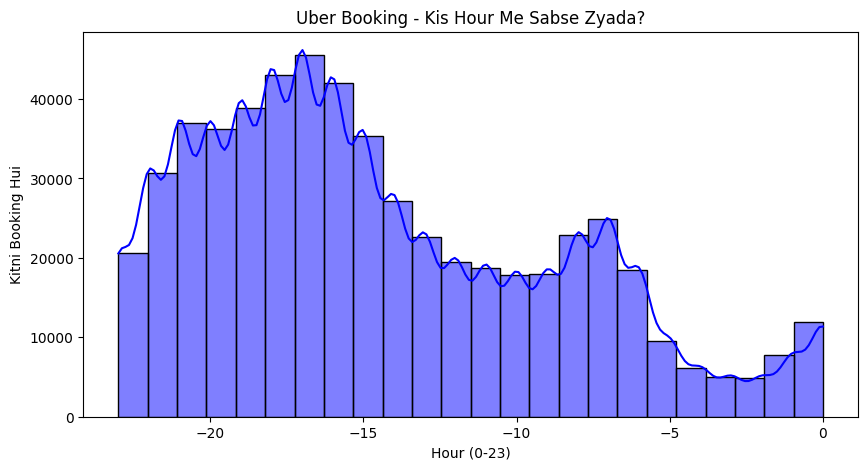

In [31]:
plt.figure(figsize=(10,5))
sns.histplot(df['Hour'], bins=24, kde=True, color='blue')
plt.title("Uber Booking - Kis Hour Me Sabse Zyada?")
plt.xlabel("Hour (0-23)")
plt.ylabel("Kitni Booking Hui")
plt.show()

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df['Base'])
plt.show()

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(df['Lat'], bins=50, color='red')
plt.title("Latitude ka Histplot")
plt.show()

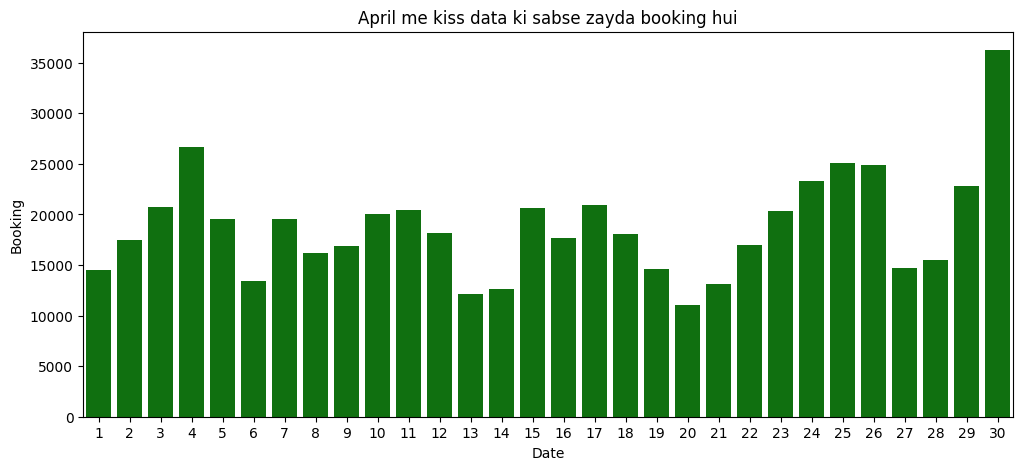

In [33]:
df['Day'] = df['Date/Time'].dt.day

plt.figure(figsize=(12,5))
sns.countplot(x='Day', data=df,color='green')
plt.title("April me kiss data ki sabse zayda booking hui")
plt.xlabel("Date")
plt.ylabel("Booking")
plt.show()

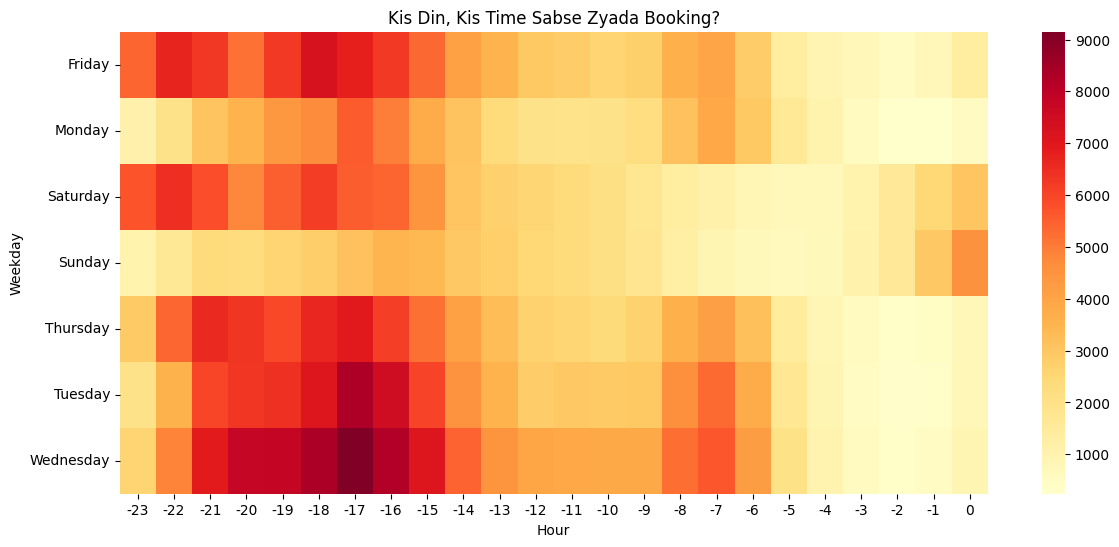

In [34]:
df['Weekday'] = df['Date/Time'].dt.day_name()

# Heatmap ke liye table banana
pivot = df.groupby(['Weekday','Hour']).size().unstack()

plt.figure(figsize=(14,6))
sns.heatmap(pivot, cmap='YlOrRd')
plt.title("Kis Din, Kis Time Sabse Zyada Booking?")
plt.show()

/tmp/ipykernel_546/288551085.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Base', data=df, order=df['Base'].value_counts().index, palette='viridis')


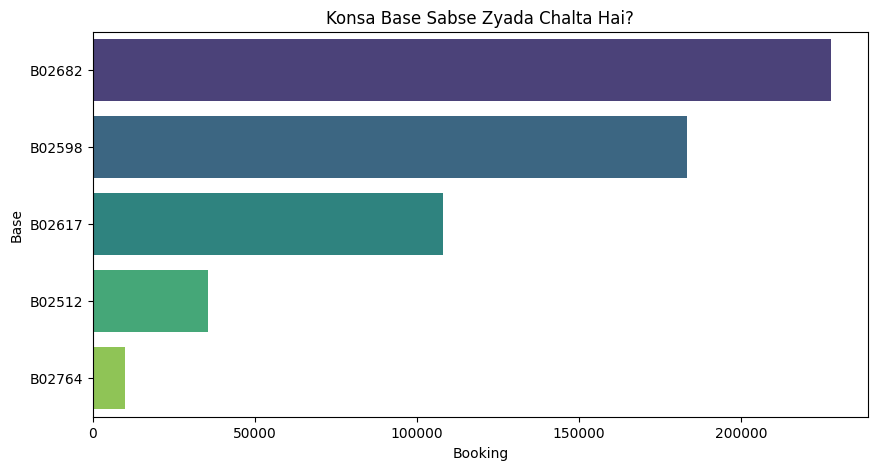

In [35]:
plt.figure(figsize=(10,5))
sns.countplot(y='Base', data=df, order=df['Base'].value_counts().index, palette='viridis')
plt.title("Konsa Base Sabse Zyada Chalta Hai?")
plt.xlabel("Booking")
plt.show()

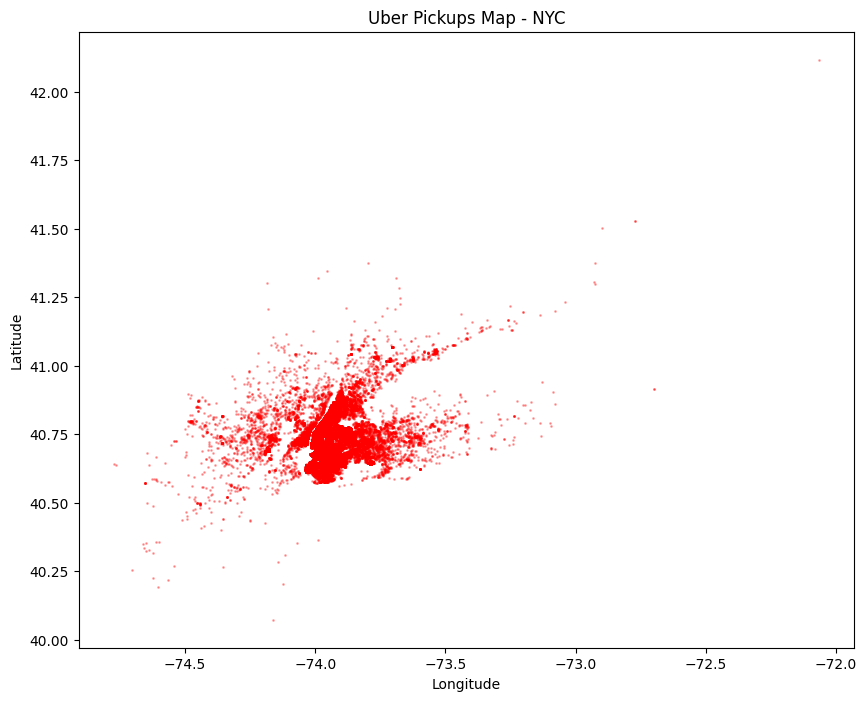

In [36]:
plt.figure(figsize=(10,8))
plt.scatter(df['Lon'], df['Lat'], s=1, alpha=0.3, color='red')
plt.title("Uber Pickups Map - NYC")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()